# COMPASS for cross-modal alignment

Given a few candidate vision encoders and language models, which pairs are worth aligning
(e.g. with a small learned adapter)? COMPASS answers this **before** any training, from
forward passes over a small paired probe set: here, the 1024 WIT image-caption pairs from
the Platonic Representation Hypothesis.

In [1]:
import matplotlib.pyplot as plt
import compass

In [2]:
VISION = [
    "vit_base_patch16_clip_224.laion2b",   # contrastive vision-language
    "vit_base_patch14_dinov2.lvd142m",     # self-distillation
    "vit_base_patch16_224.augreg_in21k",   # supervised classification
    "vit_base_patch16_224.mae",            # masked reconstruction
]
TEXT = [
    "sentence-transformers/all-roberta-large-v1",
    "allenai/OLMo-1B-hf",
    "bigscience/bloomz-560m",
]

images, captions = compass.load_wit_probe()
len(images), captions[0]

(1024,
 'Figure 2 of Paper. Pseudorhabdosynochus sulamericanus from Hyporthodus haifensis. (A) composite, ventral view; tegumental scales not drawn. (B, C) male quadriloculate organ. (D) sclerotised vagina. (A, C) carmine; (B, D) Berlese.')

## 1. Embed every model once

Each model is embedded once, no matter how many pairs it takes part in.
Features keep every layer (`[N, layers, dim]`), and the overlap uses the best layer pair.

In [3]:
vision = {m: compass.extract_vision_features(m, images) for m in VISION}
text = {m: compass.extract_text_features(m, captions) for m in TEXT}
{m: tuple(f.shape) for m, f in {**vision, **text}.items()}

{'vit_base_patch16_clip_224.laion2b': (1024, 12, 768),
 'vit_base_patch14_dinov2.lvd142m': (1024, 12, 768),
 'vit_base_patch16_224.augreg_in21k': (1024, 12, 768),
 'vit_base_patch16_224.mae': (1024, 12, 768),
 'sentence-transformers/all-roberta-large-v1': (1024, 25, 1024),
 'allenai/OLMo-1B-hf': (1024, 17, 2048),
 'bigscience/bloomz-560m': (1024, 25, 1024)}

## 2. Score and rank all pairs

* **ease**: calibrated mutual k-NN overlap of the pair (k = 10).
* **ceiling**: mean overlap of the vision encoder with a library of text encoders.
  By default the candidate text models act as the library. Pass `text_library=...`
  to use a larger one.

Pairs are ranked by the product of the two, and each axis is split at its median to assign the regimes.

In [4]:
ranking = compass.score_alignment(vision, text)
ranking.round(3)

,rank,vision,text,ease,ceiling,compass,regime
0,1,vit_base_patch16_clip_224.laion2b,sentence-transformers/all-roberta-large-v1,0.152,0.124,0.019,act now
1,2,vit_base_patch16_clip_224.laion2b,allenai/OLMo-1B-hf,0.111,0.124,0.014,act now
2,3,vit_base_patch16_clip_224.laion2b,bigscience/bloomz-560m,0.110,0.124,0.014,act now
3,4,vit_base_patch14_dinov2.lvd142m,sentence-transformers/all-roberta-large-v1,0.115,0.096,0.011,act now
4,5,vit_base_patch16_224.augreg_in21k,sentence-transformers/all-roberta-large-v1,0.115,0.092,0.011,ceiling-limited
5,6,vit_base_patch14_dinov2.lvd142m,bigscience/bloomz-560m,0.088,0.096,0.008,act now
6,7,vit_base_patch14_dinov2.lvd142m,allenai/OLMo-1B-hf,0.085,0.096,0.008,budget-limited
7,8,vit_base_patch16_224.augreg_in21k,allenai/OLMo-1B-hf,0.082,0.092,0.008,incompatible
8,9,vit_base_patch16_224.augreg_in21k,bigscience/bloomz-560m,0.079,0.092,0.007,incompatible
9,10,vit_base_patch16_224.mae,sentence-transformers/all-roberta-large-v1,0.059,0.050,0.003,incompatible


## 3. Phase diagram

Splitting both axes at their median gives the four regimes:
*act now*, *budget-limited* (more data / compute or a stronger partner),
*ceiling-limited* (switch paradigm), and *incompatible*.

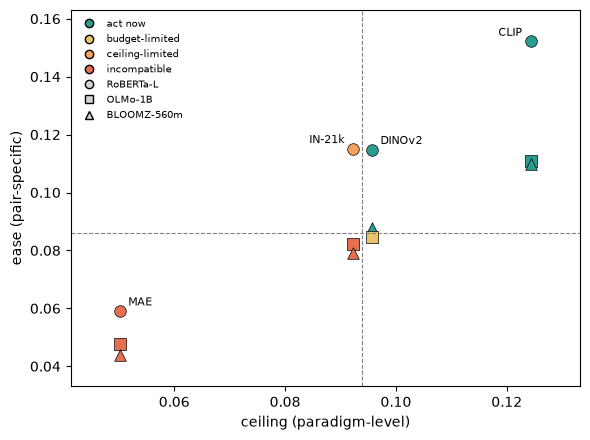

In [5]:
short = {
    "vit_base_patch16_clip_224.laion2b": "CLIP",
    "vit_base_patch14_dinov2.lvd142m": "DINOv2",
    "vit_base_patch16_224.augreg_in21k": "IN-21k",
    "vit_base_patch16_224.mae": "MAE",
    "sentence-transformers/all-roberta-large-v1": "RoBERTa-L",
    "allenai/OLMo-1B-hf": "OLMo-1B",
    "bigscience/bloomz-560m": "BLOOMZ-560m",
}
colors = {"act now": "#2a9d8f", "budget-limited": "#e9c46a", "ceiling-limited": "#f4a261", "incompatible": "#e76f51"}
markers = dict(zip(TEXT, ["o", "s", "^"]))

fig, ax = plt.subplots(figsize=(6, 4.5))
for _, r in ranking.iterrows():
    ax.scatter(r.ceiling, r.ease, s=70, color=colors[r.regime], marker=markers[r.text], edgecolor="k", lw=0.5)
# label each vision encoder's column (neighboring columns label left / right)
cols = ranking.groupby("vision").agg(ceiling=("ceiling", "first"), ease=("ease", "max")).sort_values("ceiling")
for i, (v, r) in enumerate(cols.iterrows()):
    ha = "right" if i % 2 == 1 else "left"
    ax.annotate(short[v], (r.ceiling, r.ease), xytext=(-6 if ha == "right" else 6, 4), textcoords="offset points",
                ha=ha, fontsize=8)
ax.margins(x=0.12, y=0.1)
ax.axvline(ranking["ceiling"].median(), color="grey", ls="--", lw=0.8)
ax.axhline(ranking["ease"].median(), color="grey", ls="--", lw=0.8)
handles = [plt.Line2D([], [], ls="", marker="o", color=c, markeredgecolor="k", label=k) for k, c in colors.items()]
handles += [plt.Line2D([], [], ls="", marker=m, color="lightgrey", markeredgecolor="k", label=short[t]) for t, m in markers.items()]
ax.legend(handles=handles, fontsize=7, frameon=False, loc="upper left")
ax.set_xlabel("ceiling (paradigm-level)")
ax.set_ylabel("ease (pair-specific)")
plt.tight_layout()